#### Objective

The objective of this project is to develop a **Supervised Machine Learning model** to predict used car selling prices based on the vehicle characteristics available in the dataset.

The dataset was obtained from Kaggle:
[Car Price Prediction Dataset](https://www.kaggle.com/datasets/sukhmandeepsinghbrar/car-price-prediction-dataset).

The **business objective** is to build a machine learning model that can assist in estimating used car selling prices based on various vehicle features, such as vehicle age, mileage, fuel type, and other relevant characteristics.

The model's performance will be evaluated using three regression metrics:

1. **Mean Absolute Error (MAE):** Measures the average absolute difference between predicted and actual car prices.
2. **Root Mean Squared Error (RMSE):** Measures prediction errors while giving greater weight to larger errors.
3. **R-Squared (R²):** Measures how well the model explains the variation in used car prices.


# 1. Import Libraries

In [183]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import ( mean_absolute_error, mean_squared_error, r2_score)
import pickle
import warnings
warnings.filterwarnings('ignore')
from scipy.stats import spearmanr, kendalltau
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from sklearn.model_selection import cross_validate
from sklearn.model_selection import RandomizedSearchCV
import joblib

# 2. Data Loading

In [83]:
df = pd.read_csv('cardekho.csv')

In [84]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78,5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.2,5.0


In [85]:
df.shape

(8128, 12)

# Eksploratory Data Analysis (EDA)

#### 1. Dataset Information

In [86]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   name                8128 non-null   object 
 1   year                8128 non-null   int64  
 2   selling_price       8128 non-null   int64  
 3   km_driven           8128 non-null   int64  
 4   fuel                8128 non-null   object 
 5   seller_type         8128 non-null   object 
 6   transmission        8128 non-null   object 
 7   owner               8128 non-null   object 
 8   mileage(km/ltr/kg)  7907 non-null   float64
 9   engine              7907 non-null   float64
 10  max_power           7913 non-null   object 
 11  seats               7907 non-null   float64
dtypes: float64(3), int64(3), object(6)
memory usage: 762.1+ KB


- The `max_power` column is currently stored as an **object data type**, although it should be **numerical**.


#### 2. Descriptive Statistic

In [87]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
year,8128.0,2013.804011,4.044249,1983.0,2011.00,2015.0,2017.00,2020.0
selling_price,8128.0,638271.807702,806253.403508,29999.0,254999.00,450000.0,675000.00,10000000.0
km_driven,8128.0,69819.510827,56550.554958,1.0,35000.00,60000.0,98000.00,2360457.0
mileage(km/ltr/kg),7907.0,19.418783,4.037145,0.0,16.78,19.3,22.32,42.0
engine,7907.0,1458.625016,503.916303,624.0,1197.00,1248.0,1582.00,3604.0
seats,7907.0,5.416719,0.959588,2.0,5.00,5.0,5.00,14.0


In [88]:
df.describe(include='object').T

,count,unique,top,freq
name,8128,2058,Maruti Swift Dzire VDI,129
fuel,8128,4,Diesel,4402
seller_type,8128,3,Individual,6766
transmission,8128,2,Manual,7078
owner,8128,5,First Owner,5289
max_power,7913,320,74,377


#### 3. Missing Value

In [89]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': df.isnull().sum() / len(df)*100
})

missing

,Missing Values,Percentage
name,0,0.000000
year,0,0.000000
selling_price,0,0.000000
km_driven,0,0.000000
fuel,0,0.000000
seller_type,0,0.000000
transmission,0,0.000000
owner,0,0.000000
mileage(km/ltr/kg),221,2.718996
engine,221,2.718996


##### Analysis

- Missing values are identified in the `mileage`, `engine`, `max_power`, and `seats` columns.
- These missing values will be handled using **SimpleImputer** during the data preprocessing stage.


#### 4. Duplicate Data

In [90]:
print('Jumlah duplicate data:' ,df.duplicated().sum())

Jumlah duplicate data: 1202


#### 5. Target Distribution

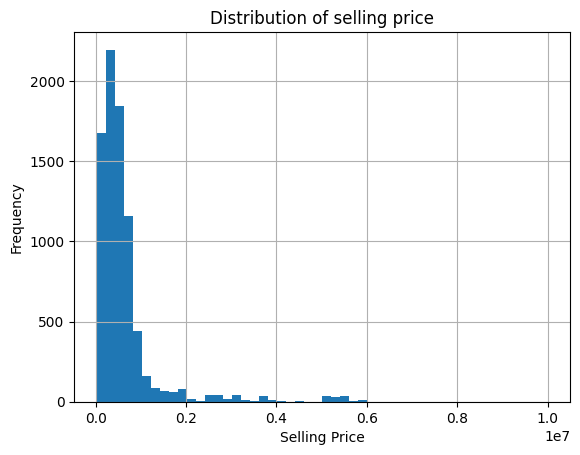

In [91]:
target = 'selling_price'

df[target].hist(bins=50)
plt.xlabel('Selling Price')
plt.ylabel('Frequency')
plt.title('Distribution of selling price')
plt.show()

In [92]:
print('Skewness:', df['selling_price'].skew())

Skewness: 4.193533440675855


##### Analysis
- The `selling_price` column exhibits a **right-skewed distribution (positive skewness)** due to the presence of extremely high outliers.


#### 6. Selling Price and Car Year Corellation

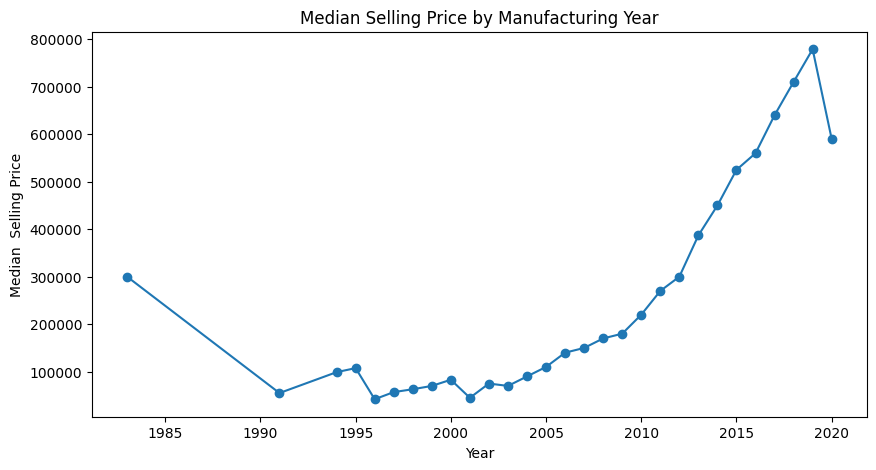

In [93]:
price_by_year = (
    df.groupby('year')['selling_price']
    .median()
    .sort_index()
)

plt.figure(figsize=(10,5))
plt.plot(price_by_year.index,
         price_by_year.values,
         marker='o')

plt.xlabel('Year')
plt.ylabel('Median  Selling Price')
plt.title('Median Selling Price by Manufacturing Year')
plt.show()

##### Analysis
- Cars with **newer production years** generally have higher selling prices.
- However, some cars manufactured **before 1990** also have relatively high selling prices, possibly because they are considered **classic, collectible, or antique cars**.


#### 7. Selling Price by Fuel Type

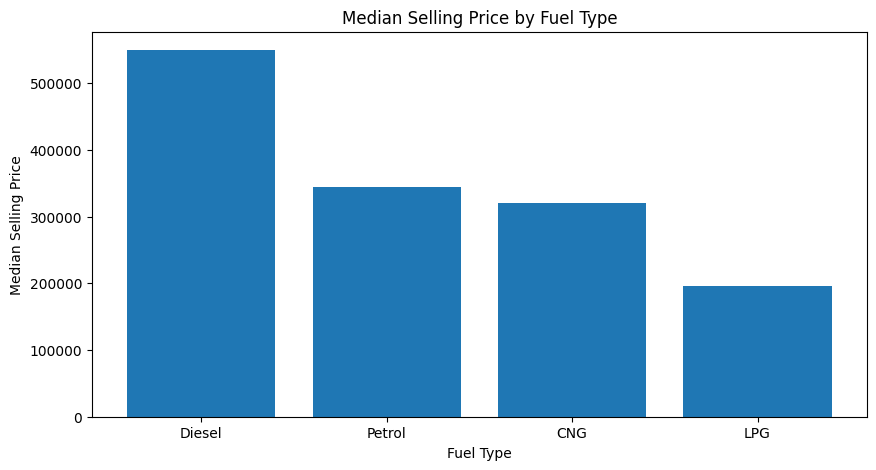

In [94]:
fuel_type_price = (
    df.groupby('fuel')['selling_price']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,5))
plt.bar(
    fuel_type_price.index,
    fuel_type_price.values
)

plt.xlabel('Fuel Type')
plt.ylabel('Median Selling Price')
plt.title('Median Selling Price by Fuel Type')
plt.show()

##### Analysis
- Cars with **Diesel fuel type** have the highest selling prices, followed by cars using **Petrol**.


#### 8. Seling Price by Transmission

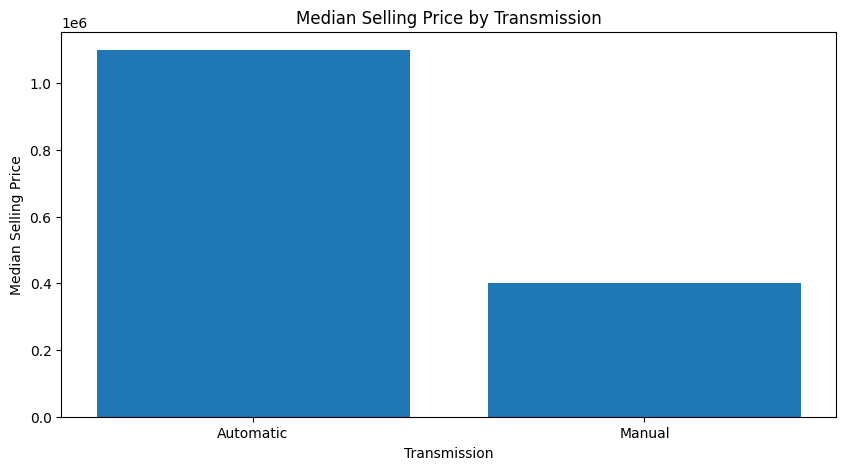

In [95]:
transmission_price = (
    df.groupby('transmission')['selling_price']
    .median()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(
    transmission_price.index,
    transmission_price.values
)

plt.xlabel('Transmission')
plt.ylabel('Median Selling Price')
plt.title('Median Selling Price by Transmission')
plt.show()

##### Analysis
- Cars with **automatic transmissions** generally have higher selling prices compared to cars with **manual transmissions**.


# 4. Data Cleaning

#### 1. Handle Duplicate

In [96]:
# buat df baru
df_clean = df.copy()

In [97]:
df_clean = df_clean.drop_duplicates()
print('Shape after drop duplicate', df_clean.shape)

Shape after drop duplicate (6926, 12)


##### Analysis
- Since these rows are **identical duplicates**, they are removed to prevent redundant observations from unnecessarily influencing the model during training.


#### 2. Convert max_power to Numeric

In [98]:
df_clean['max_power'] = pd.to_numeric(
    df_clean['max_power'],
    errors='coerce'
)

In [99]:
df_clean['max_power'].dtype

dtype('float64')

# 5. Feature Engineering

#### 1. Car Age = Year

In [100]:
reference_year = df_clean['year'].max()

df_clean['car_age'] = reference_year - df_clean['year']

In [101]:
df_clean[['year', 'car_age']].head()

,year,car_age
0,2014,6
1,2014,6
2,2006,14
3,2010,10
4,2007,13


In [102]:
df_clean.drop(columns='year', inplace=True)

##### Analysis
- Since the dataset only includes data up to **2020**, we use **2020 as the reference year** to calculate the age of each car.


#### 2. Ectract Brand from Name

In [103]:
df_clean['brand'] = (
    df_clean['name']
    .str.split()
    .str[0]
)

In [104]:
df_clean[['name', 'brand']].head()

,name,brand
0,Maruti Swift Dzire VDI,Maruti
1,Skoda Rapid 1.5 TDI Ambition,Skoda
2,Honda City 2017-2020 EXi,Honda
3,Hyundai i20 Sportz Diesel,Hyundai
4,Maruti Swift VXI BSIII,Maruti


In [105]:
df_clean.drop(columns='name',inplace=True)

##### Analysis
- The `name` column contains **2,058 unique values**, meaning that applying **One-Hot Encoding** to all car names would generate too many features and increase model complexity.
- Therefore, **the car brand is extracted from the first word of each car name** to reduce the number of unique categories and simplify the encoding process.


#### 3. Final Dataset

In [106]:
df_clean.head(10)

,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,car_age,brand
0,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,6,Maruti
1,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,6,Skoda
2,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,14,Honda
3,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,10,Hyundai
4,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,13,Maruti
5,440000,45000,Petrol,Individual,Manual,First Owner,20.14,1197.0,81.86,5.0,3,Hyundai
6,96000,175000,LPG,Individual,Manual,First Owner,17.30,1061.0,57.50,5.0,13,Maruti
7,45000,5000,Petrol,Individual,Manual,Second Owner,16.10,796.0,37.00,4.0,19,Maruti
8,350000,90000,Diesel,Individual,Manual,First Owner,23.59,1364.0,67.10,5.0,9,Toyota
9,200000,169000,Diesel,Individual,Manual,First Owner,20.00,1399.0,68.10,5.0,7,Ford


In [107]:
df_clean.info(10)

<class 'pandas.core.frame.DataFrame'>
Index: 6926 entries, 0 to 8125
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   selling_price       6926 non-null   int64  
 1   km_driven           6926 non-null   int64  
 2   fuel                6926 non-null   object 
 3   seller_type         6926 non-null   object 
 4   transmission        6926 non-null   object 
 5   owner               6926 non-null   object 
 6   mileage(km/ltr/kg)  6718 non-null   float64
 7   engine              6718 non-null   float64
 8   max_power           6720 non-null   float64
 9   seats               6718 non-null   float64
 10  car_age             6926 non-null   int64  
 11  brand               6926 non-null   object 
dtypes: float64(4), int64(3), object(5)
memory usage: 703.4+ KB


# 6. Split Feature & Target 

In [108]:
X = df_clean.drop(columns='selling_price')
y = df_clean['selling_price']

In [109]:
X.head()

,km_driven,fuel,seller_type,transmission,owner,mileage(km/ltr/kg),engine,max_power,seats,car_age,brand
0,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,5.0,6,Maruti
1,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,5.0,6,Skoda
2,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,5.0,14,Honda
3,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,5.0,10,Hyundai
4,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,5.0,13,Maruti


In [110]:
y.head()

0    450000
1    370000
2    158000
3    225000
4    130000
Name: selling_price, dtype: int64

##### Analysis
- The dataset is divided into **features (X)** and the **target variable (y)**. Since the objective is to predict car selling prices, the `selling_price` column is removed from the feature set and assigned as the target variable.


# 7. Train Test Split

In [111]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [112]:
print('X Train:', X_train.shape)
print('X Test :', X_test.shape)
print('y Train:', y_train.shape)
print('y Test :', y_test.shape)

X Train: (5540, 11)
X Test : (1386, 11)
y Train: (5540,)
y Test : (1386,)


##### Analysis

- The dataset is split into **80% training data and 20% testing data**.
- **Data splitting is performed before missing value handling, feature scaling, and encoding** to prevent data leakage and ensure that the model is evaluated on unseen data.

# 8. Feature Selection (Numerical, Categorical, dan Encoding)

#### 1. Define Numerical dan Categorical Column

In [113]:
num_cols = [
    'km_driven',
    'mileage(km/ltr/kg)',
    'engine',
    'max_power',
    'seats',
    'car_age'
]

cat_cols = [
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'brand'
]

In [114]:
print('Numerical Features:')
print(num_cols)

print('\nCategorical Features:')
print(cat_cols)

Numerical Features:
['km_driven', 'mileage(km/ltr/kg)', 'engine', 'max_power', 'seats', 'car_age']

Categorical Features:
['fuel', 'seller_type', 'transmission', 'owner', 'brand']


#### 2. Spearman Correlation Test

In [115]:
spearman_results =[]

for feature in num_cols:
    temp_data = pd.DataFrame({   #Buat tempt data karena ada missing value
        'feature': X_train[feature],
        'target' : y_train
    }).dropna()

    correlation, p_value = spearmanr(
        temp_data['feature'],
        temp_data['target']
    )

    spearman_results.append({
        'Feature' : feature,
        'Spearman Correlation' : correlation,
        'Spearman P-Value' : p_value
    })

In [116]:
spearman_df = pd.DataFrame(spearman_results)

spearman_df['Abs Spearman'] = (
    spearman_df['Spearman Correlation'].abs()
)
spearman_df = spearman_df.sort_values(
    'Abs Spearman',
    ascending=False
)
spearman_df

,Feature,Spearman Correlation,Spearman P-Value,Abs Spearman
5,car_age,-0.705075,0.000000e+00,0.705075
3,max_power,0.638555,0.000000e+00,0.638555
2,engine,0.484835,0.000000e+00,0.484835
4,seats,0.318750,4.900301e-127,0.318750
0,km_driven,-0.287858,3.563435e-106,0.287858
1,mileage(km/ltr/kg),0.013195,3.337433e-01,0.013195


In [117]:
spearman_df['Significant correlation'] = np.where(
    spearman_df['Spearman P-Value'] < 0.05,
    'Yes',
    'No'
)
spearman_df

,Feature,Spearman Correlation,Spearman P-Value,Abs Spearman,Significant correlation
5,car_age,-0.705075,0.000000e+00,0.705075,Yes
3,max_power,0.638555,0.000000e+00,0.638555,Yes
2,engine,0.484835,0.000000e+00,0.484835,Yes
4,seats,0.318750,4.900301e-127,0.318750,Yes
0,km_driven,-0.287858,3.563435e-106,0.287858,Yes
1,mileage(km/ltr/kg),0.013195,3.337433e-01,0.013195,No


#### Hypothesis Testing

**Null Hypothesis (H0):**
- There is no statistically significant monotonic relationship between the feature and `selling_price`.

**Alternative Hypothesis (H1):**
- There is a statistically significant monotonic relationship between the feature and `selling_price`.

**Significance Level:** α = 0.05

**Decision Criteria:**

- **p-value < 0.05**
  - Reject H0.
  - There is a statistically significant monotonic relationship between the feature and `selling_price` (**Yes**).

- **p-value >= 0.05**
  - Fail to reject H0.
  - There is insufficient statistical evidence of a significant monotonic relationship between the feature and `selling_price` (**No**).


##### Analysis
- Based on the **Spearman Correlation Test** conducted on numerical features, several variables show a **statistically significant correlation** with `selling_price`, including `car_age`, `max_power`, `engine`, `seats`, and `km_driven`.

- Some features have **positive correlations**, while others, such as `km_driven` and `car_age`, show **negative correlations**. This is reasonable because cars with higher mileage generally have lower selling prices. Similarly, older cars tend to have lower selling prices, as previously observed during the EDA.

- However, the `mileage(km/ltr/kg)` feature does not show a **statistically significant correlation** with `selling_price`.

- Despite its insignificant correlation, **this feature will be retained based on domain knowledge**, as fuel efficiency is an important consideration for many customers when purchasing a used car. Buyers often consider whether a vehicle is fuel-efficient or has high fuel consumption, which may still influence its market value.


#### 3. Kendall Correlation Test

In [118]:
kendal_results = []

for feature in num_cols:

    temp_data = pd.DataFrame({
        'feature' : X_train[feature],
        'target' : y_train
    }).dropna()

    correlation, p_value = kendalltau(
        temp_data['feature'],
        temp_data['target']
    )
    kendal_results.append({
        'feature' : feature,
        'Kendall Correlation' : correlation,
        "Kendall P-Value" : p_value
    })

In [119]:
kendall_df = pd.DataFrame(kendal_results)

kendall_df['Abs Kendall'] = (
    kendall_df['Kendall Correlation'].abs()
)
kendall_df['Significant Correlation'] = np.where(
    kendall_df['Kendall P-Value'] < 0.05,
    'Yes',
    'No'
)
kendall_df = kendall_df.sort_values(
    'Abs Kendall',
    ascending=False
)
kendall_df

,feature,Kendall Correlation,Kendall P-Value,Abs Kendall,Significant Correlation
5,car_age,-0.536884,0.000000e+00,0.536884,Yes
3,max_power,0.470288,0.000000e+00,0.470288,Yes
2,engine,0.351688,9.416827e-309,0.351688,Yes
4,seats,0.256747,3.764200e-123,0.256747,Yes
0,km_driven,-0.194936,5.307980e-101,0.194936,Yes
1,mileage(km/ltr/kg),0.021140,2.135916e-02,0.021140,Yes


##### Hypothesis Testing

**Null Hypothesis (H0):**
- There is no statistically significant monotonic relationship between the feature and `selling_price`.

**Alternative Hypothesis (H1):**
- There is a statistically significant monotonic relationship between the feature and `selling_price`.

**Significance Level:** α = 0.05

**Decision Criteria:**

- **p-value < 0.05**
  - Reject H0.
  - There is a statistically significant monotonic relationship between the feature and `selling_price` (**Yes**).

- **p-value >= 0.05**
  - Fail to reject H0.
  - There is insufficient statistical evidence of a significant monotonic relationship between the feature and `selling_price` (**No**).


##### Analysis

- Based on the **Kendall Correlation Test**, all numerical features show a **statistically significant relationship** with `selling_price`.
- Therefore, **all features will be retained** for further modeling, as the correlation results indicate that each feature has a significant relationship with the target variable.


#### 4. Final Features

In [120]:
selected_features = (
    num_cols + cat_cols
)
selected_features

['km_driven',
 'mileage(km/ltr/kg)',
 'engine',
 'max_power',
 'seats',
 'car_age',
 'fuel',
 'seller_type',
 'transmission',
 'owner',
 'brand']

##### Total feature used : **11 features**

# 9. Preprocessing

In [121]:
numeric_pipeline = Pipeline([
    ('imputer',
    SimpleImputer(strategy='median')),
    ('scaler',
     RobustScaler())
])

- **Median imputation** is used to handle missing values because the median is more robust to outliers compared to the mean.
- **RobustScaler** is used because several numerical features contain extreme values. Feature scaling is also important because **KNN and SVR are sensitive to differences in feature scales**, which can affect their predictive performance.


In [122]:
categorical_pipeline = Pipeline([
    ('imputer',
     SimpleImputer(strategy='most_frequent')),
    ('encoder',
     OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

- **OneHotEncoder** is used because categorical features are nominal and do not have a natural numerical order.
- The parameter **`handle_unknown='ignore'`** is applied to ensure that the pipeline can still perform inference when encountering new categories that were not present during training.


In [123]:
preprocessor = ColumnTransformer([
    ('numerical',
     numeric_pipeline,
     num_cols),
    ('categorical',
     categorical_pipeline,
     cat_cols)
])

##### Analysis

Two separate preprocessing pipelines are created for **numerical and categorical features**.

**1. Numerical Pipeline**
- **SimpleImputer** with the **median strategy** is used to handle missing values because the median is more robust to outliers compared to the mean.
- **RobustScaler** is applied to scale numerical features because several columns, such as `km_driven`, contain extreme values. RobustScaler is less sensitive to outliers than StandardScaler because it uses the median and interquartile range (IQR).

**2. Categorical Pipeline**
- **SimpleImputer** with the **most_frequent strategy (mode)** is used to handle missing values in categorical features.
- **OneHotEncoder** is applied because categorical features are nominal and do not have a natural numerical order.
- The parameter **`handle_unknown='ignore'`** ensures that the pipeline can still perform inference when encountering new categories that were not present during training.

**3. ColumnTransformer**
- Both numerical and categorical pipelines are combined using **ColumnTransformer** to ensure that each feature type receives the appropriate preprocessing steps.
- This approach creates a **consistent and efficient preprocessing workflow** that can be applied during both model training and inference.


# 10. Model Definition

#### 1. Linear Regression

In [124]:
linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

#### 2. Ridge Regression

In [125]:
ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=1.0))
])

#### 3. Random Forest Regression

In [126]:
rf_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

#### 4. KNN

In [127]:
knn_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsRegressor())

])

#### 5. SVM

In [128]:
svm_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model',SVR())
])

#### 6. Decision Tree

In [129]:
dt_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

#### 7. Boosting (Gradient Boosting)

In [130]:
gb_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        random_state=42
    ))
])

# 11. Model Training

In [131]:
linear_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['km_driven',
                                                   'mileage(km/ltr/kg)',
                                                   'engine', 'max_power',
                                                   'seats', 'car_age']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['fuel', 'seller_type',
                                                   'transmission', 'owner',
                                                   'brand'])])),
                ('model', LinearRegression())])

In [132]:
ridge_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['km_driven',
                                                   'mileage(km/ltr/kg)',
                                                   'engine', 'max_power',
                                                   'seats', 'car_age']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['fuel', 'seller_type',
                                                   'transmission', 'owner',
                                                   'brand'])])),
                ('model', Ridge())])

#### Train Baseline Model (KNN, SVM, Decision Tree, Random Forest, Gradient Boosting)

In [150]:
models = {
    'KNN': knn_model,
    'SVM': svm_model,
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'Gradient Boosting': gb_model
}

In [151]:
for name, model in models.items():

    print(f'Training {name}...')

    model.fit(
        X_train,
        y_train
    )

print('\nAll baseline models have been trained.')

Training KNN...
Training SVM...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...

All baseline models have been trained.


# 12. Model Evaluation

In [ ]:
# untuk evalusai model linear regression dan ridge regression

def evaluate_model(model, X_train, X_test, y_train, y_test):
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    results = {
        'Train MAE': mean_absolute_error(y_train,y_pred_train),
        'Test MAE' : mean_absolute_error(y_test, y_pred_test),

        'Train MSE': mean_squared_error(y_train, y_pred_train),
        'Test MSE' : mean_squared_error(y_test, y_pred_test),

        'Train RMSE': np.sqrt(
            mean_squared_error(y_train, y_pred_train)),
        'Test RMSE': np.sqrt(
            mean_squared_error(y_test,y_pred_test)),
        'Train R2' : r2_score(y_train,y_pred_train),
        'Test R2'  : r2_score(y_test, y_pred_test)
    }

    return results

In [ ]:
# untuk evaluasi model baseline (KNN, SVM, decition tree, random forest)

baseline_results = {}

for name, model in models.items():

    y_pred_train = model.predict(
        X_train
    )

    y_pred_test = model.predict(
        X_test
    )

    train_mae = mean_absolute_error(
        y_train,
        y_pred_train
    )

    test_mae = mean_absolute_error(
        y_test,
        y_pred_test
    )

    train_mse = mean_squared_error(
        y_train,
        y_pred_train
    )

    test_mse = mean_squared_error(
        y_test,
        y_pred_test
    )

    train_rmse = np.sqrt(train_mse)
    test_rmse = np.sqrt(test_mse)

    train_r2 = r2_score(
        y_train,
        y_pred_train
    )

    test_r2 = r2_score(
        y_test,
        y_pred_test
    )

    baseline_results[name] = {
        'Train MAE': train_mae,
        'Test MAE': test_mae,

        'Train MSE': train_mse,
        'Test MSE': test_mse,

        'Train RMSE': train_rmse,
        'Test RMSE': test_rmse,

        'Train R2': train_r2,
        'Test R2': test_r2
    }

##### Make functions for model evaluation

#### 1. Linear Regression Evaluation

In [139]:
linear_results = evaluate_model(
    linear_model,
    X_train,
    X_test,
    y_train,
    y_test
)
linear_results 

{'Train MAE': 136974.60197509118,
 'Test MAE': 133098.65706094226,
 'Train MSE': 68325283102.734566,
 'Test MSE': 68605037120.29853,
 'Train RMSE': 261391.0539837478,
 'Test RMSE': 261925.6328049978,
 'Train R2': 0.7583444747994479,
 'Test R2': 0.6871943832051288}

#### 2. Ridge Regression Evaluation

In [140]:
ridge_results = evaluate_model(
    ridge_model,
    X_train,
    X_test,
    y_train,
    y_test
)

ridge_results

{'Train MAE': 138207.48005264418,
 'Test MAE': 133532.34681916863,
 'Train MSE': 68750482197.41237,
 'Test MSE': 67287326464.52573,
 'Train RMSE': 262203.1315553122,
 'Test RMSE': 259398.0078268253,
 'Train R2': 0.7568406140633765,
 'Test R2': 0.6932025031878266}

#### 3. Komparasi Moddel Evaluation

In [163]:
comparison = pd.DataFrame({
    'Linear Regression': linear_results,
    'Ridge Regression': ridge_results,
}).T

comparison

,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
Linear Regression,136974.601975,133098.657061,6.832528e+10,6.860504e+10,261391.053984,261925.632805,0.758344,0.687194
Ridge Regression,138207.480053,133532.346819,6.875048e+10,6.728733e+10,262203.131555,259398.007827,0.756841,0.693203


In [154]:
baseline_df = pd.DataFrame(
    baseline_results
).T

baseline_df

,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2
KNN,81044.937040,96623.527273,2.982207e+10,4.834899e+10,172690.675837,219884.048542,0.894524,0.779552
SVM,282217.584995,259364.179623,2.972905e+11,2.292257e+11,545243.512336,478775.202049,-0.051469,-0.045158
Decision Tree,3326.805776,92927.454064,2.112972e+08,2.841548e+10,14536.067078,168568.913180,0.999253,0.870439
Random Forest,30750.584630,73667.595731,4.287968e+09,1.729757e+10,65482.580198,131520.230049,0.984834,0.921131
Gradient Boosting,80373.781541,82902.443284,1.613706e+10,1.746593e+10,127031.730210,132158.746269,0.942926,0.920364


##### Analysis

- Based on the initial model evaluation, **Random Forest** achieves a **training MAE of 30,750.58** and a **testing MAE of 73,667.60**, making it the model with the lowest prediction error on the test set. However, the significant gap between training and testing MAE indicates **potential overfitting**, as the model performs considerably better on the training data.

- On the other hand, **Gradient Boosting** achieves a **training MAE of 80,373.78** and a **testing MAE of 82,902.44**, demonstrating **more consistent performance** between the training and testing datasets.

- Although Random Forest achieves a lower testing MAE, Gradient Boosting shows better generalization consistency with a smaller performance gap.

- Therefore, both models will be further evaluated using **Cross-Validation** to assess their stability and generalization performance before selecting the best model.


#### 4. Cross Validation

In [158]:
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

In [159]:
cv_results = []

for name, model in models.items():

    print(f'Cross validating {name}...')

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,

        'CV MAE Mean':
            -scores['test_mae'].mean(),

        'CV MAE Std':
            scores['test_mae'].std(),

        'CV RMSE Mean':
            -scores['test_rmse'].mean(),

        'CV RMSE Std':
            scores['test_rmse'].std(),

        'CV R2 Mean':
            scores['test_r2'].mean(),

        'CV R2 Std':
            scores['test_r2'].std()
    })

Cross validating KNN...
Cross validating SVM...
Cross validating Decision Tree...
Cross validating Random Forest...
Cross validating Gradient Boosting...


In [160]:
cv_df = pd.DataFrame(cv_results)

cv_df

,Model,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,KNN,105670.691697,3108.525441,225555.845546,23016.842510,0.818901,0.017611
1,SVM,282256.071353,6316.962197,543769.206655,40555.914938,-0.052550,0.006190
2,Decision Tree,106523.715854,1007.930758,231167.160082,18529.473313,0.809142,0.018066
3,Random Forest,81581.077926,3681.724646,175590.892877,34883.277093,0.889215,0.030196
4,Gradient Boosting,88829.757115,950.676322,173924.777136,30886.436780,0.892721,0.021819


In [161]:
baseline_comparison = (
    baseline_df
    .reset_index()
    .rename(columns={'index': 'Model'})
)

model_comparison = pd.merge(
    baseline_comparison,
    cv_df,
    on='Model'
)

model_comparison

,Model,Train MAE,Test MAE,Train MSE,Test MSE,Train RMSE,Test RMSE,Train R2,Test R2,CV MAE Mean,CV MAE Std,CV RMSE Mean,CV RMSE Std,CV R2 Mean,CV R2 Std
0,KNN,81044.937040,96623.527273,2.982207e+10,4.834899e+10,172690.675837,219884.048542,0.894524,0.779552,105670.691697,3108.525441,225555.845546,23016.842510,0.818901,0.017611
1,SVM,282217.584995,259364.179623,2.972905e+11,2.292257e+11,545243.512336,478775.202049,-0.051469,-0.045158,282256.071353,6316.962197,543769.206655,40555.914938,-0.052550,0.006190
2,Decision Tree,3326.805776,92927.454064,2.112972e+08,2.841548e+10,14536.067078,168568.913180,0.999253,0.870439,106523.715854,1007.930758,231167.160082,18529.473313,0.809142,0.018066
3,Random Forest,30750.584630,73667.595731,4.287968e+09,1.729757e+10,65482.580198,131520.230049,0.984834,0.921131,81581.077926,3681.724646,175590.892877,34883.277093,0.889215,0.030196
4,Gradient Boosting,80373.781541,82902.443284,1.613706e+10,1.746593e+10,127031.730210,132158.746269,0.942926,0.920364,88829.757115,950.676322,173924.777136,30886.436780,0.892721,0.021819


In [162]:
best_model_name = cv_df.loc[
    cv_df['CV R2 Mean'].idxmax(),
    'Model'
]

best_model_name

'Gradient Boosting'

In [165]:
best_model_name = 'Gradient Boosting'

best_baseline_model = models[best_model_name]
best_baseline_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['km_driven',
                                                   'mileage(km/ltr/kg)',
                                                   'engine', 'max_power',
                                                   'seats', 'car_age']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['fuel', 'seller_type',
                                                   'transmission', 'owner',
                                                   'brand'])])),
                ('model', GradientBoostingRegressor(random_state=42))])

##### Analysis

- Initially, **Random Forest** and **Gradient Boosting** were selected as the two main candidate models based on their initial evaluation results.

- After performing **Cross-Validation**, **Gradient Boosting** demonstrated better consistency and stability across different data splits.

- Although **Random Forest** achieved a lower MAE on the holdout test set, **Gradient Boosting** showed a smaller performance gap between training and testing results, indicating better generalization consistency.

- Therefore, **Gradient Boosting** is selected as the best candidate for further **Hyperparameter Tuning** to improve its predictive performance while maintaining model stability.

- **Selected Model for Hyperparameter Tuning: `Gradient Boosting`**


# 13. Hyperparameter Tuning

#### 1. Parameter Distribution

In [166]:
parameter_distribution = {
    
    'model__n_estimators': [
        100,
        200,
        300
    ],
    
    'model__learning_rate': [
        0.03,
        0.05,
        0.1
    ],
    
    'model__subsample': [
        0.8,
        0.9,
        1.0
    ]
}

##### Hyperparameter Tuning

Each hyperparameter has a different function:

- **`n_estimators`**: Determines the number of boosting stages (trees) used in the model.
- **`learning_rate`**: Controls the contribution of each tree to the model's predictions.
- **`subsample`**: Determines the proportion of training data used at each boosting stage.


#### 2. RandomizedSearchCV

In [167]:
randomized_search_gb = RandomizedSearchCV(
    estimator=best_baseline_model,
    param_distributions=parameter_distribution,
    n_iter=15,
    scoring='r2',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

##### Hyperparameter Tuning Analysis

- **Hyperparameter tuning** is performed using `RandomizedSearchCV` to efficiently search for the best combination of hyperparameters.
- A total of **15 hyperparameter combinations** are randomly selected and evaluated.
- **R² Score** is used as the evaluation metric to determine the best hyperparameter combination. A higher average cross-validation R² score indicates better predictive performance.
- Each hyperparameter combination is evaluated using **5-Fold Cross-Validation** to assess model performance across different data splits.
- The combination with the **highest average cross-validation R² score** is selected as the best hyperparameter configuration.


In [168]:
randomized_search_gb.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numerical',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                RobustScaler())]),
                                                                               ['km_driven',
                                                                                'mileage(km/ltr/kg)',
                                                                                'engine',
                                                                                'max_power',
                                                                                'seats',
                                                                                'car_age']),
                                                                              ('categorical',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='most_freq...
                                                                                                OneHotEncoder(handle_unknown='ignore',
                                                                                                              sparse_output=False))]),
                                                                               ['fuel',
                                                                                'seller_type',
                                                                                'transmission',
                                                                                'owner',
                                                                                'brand'])])),
                                             ('model',
                                              GradientBoostingRegressor(random_state=42))]),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'model__learning_rate': [0.03, 0.05,
                                                                 0.1],
                                        'model__n_estimators': [100, 200, 300],
                                        'model__subsample': [0.8, 0.9, 1.0]},
                   random_state=42, scoring='r2', verbose=1)

In [169]:
print('Best Parameters:')
print(randomized_search_gb.best_params_)

print('\nBest CV R2:')
print(randomized_search_gb.best_score_)

Best Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 300, 'model__learning_rate': 0.1}

Best CV R2:
0.9016916694793091


##### Hyperparameter Tuning Results Analysis

Based on the results of `RandomizedSearchCV`, the best hyperparameter combination for the **Gradient Boosting Regressor** is:

1. **`n_estimators=300`**: Uses 300 boosting stages (trees).
2. **`learning_rate=0.1`**: Controls the contribution of each boosting stage to the model's predictions.
3. **`subsample=0.8`**: Uses 80% of the training data at each boosting stage.

- This combination achieves an **average Cross-Validation R² Score of 0.9017 (90.17%)**.
- This indicates that the model explains approximately **90.17% of the variance in the target variable** across the cross-validation folds, on average.
- The results demonstrate **strong predictive performance**, suggesting that the selected hyperparameter combination is effective for predicting used car selling prices.



#### 3. Model Optimization Evaluation

In [172]:
best_gb_model = (
    randomized_search_gb.best_estimator_
)

In [173]:
y_pred_train_gb_tuned = (
    best_gb_model.predict(
        X_train
    )
)

y_pred_test_gb_tuned = (
    best_gb_model.predict(
        X_test
    )
)

In [174]:
gb_tuned_train_mae = mean_absolute_error(
    y_train,
    y_pred_train_gb_tuned
)

gb_tuned_test_mae = mean_absolute_error(
    y_test,
    y_pred_test_gb_tuned
)


gb_tuned_train_mse = mean_squared_error(
    y_train,
    y_pred_train_gb_tuned
)

gb_tuned_test_mse = mean_squared_error(
    y_test,
    y_pred_test_gb_tuned
)


gb_tuned_train_rmse = np.sqrt(
    gb_tuned_train_mse
)

gb_tuned_test_rmse = np.sqrt(
    gb_tuned_test_mse
)


gb_tuned_train_r2 = r2_score(
    y_train,
    y_pred_train_gb_tuned
)

gb_tuned_test_r2 = r2_score(
    y_test,
    y_pred_test_gb_tuned
)

In [175]:
gb_tuned_results = pd.DataFrame({
    
    'Metric': [
        'MAE',
        'MSE',
        'RMSE',
        'R2'
    ],
    
    'Train': [
        gb_tuned_train_mae,
        gb_tuned_train_mse,
        gb_tuned_train_rmse,
        gb_tuned_train_r2
    ],
    
    'Test': [
        gb_tuned_test_mae,
        gb_tuned_test_mse,
        gb_tuned_test_rmse,
        gb_tuned_test_r2
    ]
})

gb_tuned_results

,Metric,Train,Test
0,MAE,6.488165e+04,7.483081e+04
1,MSE,8.952796e+09,1.548868e+10
2,RMSE,9.461922e+04,1.244535e+05
3,R2,9.683354e-01,9.293792e-01


#### 4. Actual Vs Predicted

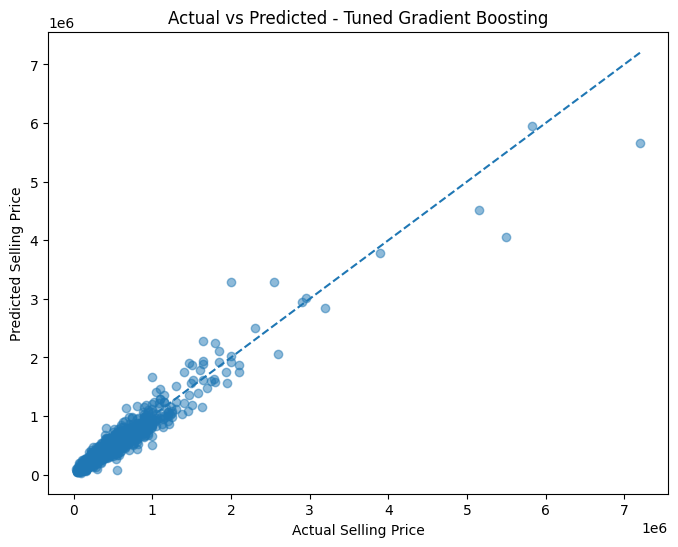

In [181]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_test_gb_tuned,
    alpha=0.5
)

min_value = min(
    y_test.min(),
    y_pred_test_gb_tuned.min()
)

max_value = max(
    y_test.max(),
    y_pred_test_gb_tuned.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--'
)

plt.xlabel('Actual Selling Price')
plt.ylabel('Predicted Selling Price')

plt.title(
    'Actual vs Predicted - Tuned Gradient Boosting'
)

plt.show()

#### 5. Residual Analiysis

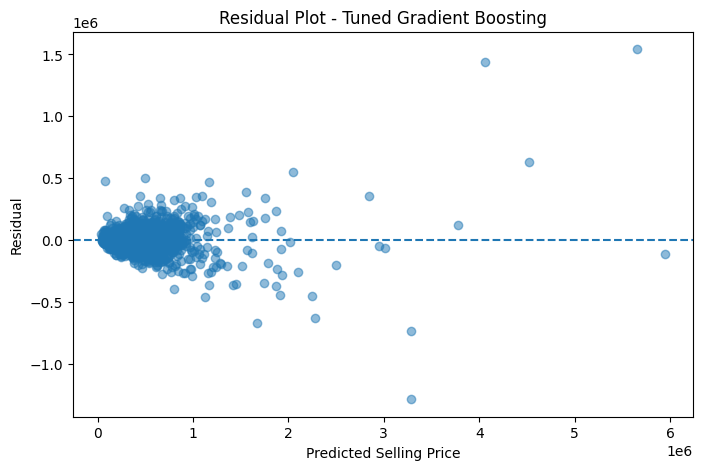

In [182]:
residuals = (
    y_test
    - y_pred_test_gb_tuned
)

plt.figure(figsize=(8, 5))

plt.scatter(
    y_pred_test_gb_tuned,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Predicted Selling Price')
plt.ylabel('Residual')

plt.title(
    'Residual Plot - Tuned Gradient Boosting'
)

plt.show()

#### 4. Comparison Before Vs After Tuning

In [177]:
gb_before = baseline_df.loc[
    'Gradient Boosting'
]

comparison_gb = pd.DataFrame({
    
    'Metric': [
        'Train MAE',
        'Test MAE',
        'Train RMSE',
        'Test RMSE',
        'Train R2',
        'Test R2'
    ],
    
    'Before Tuning': [
        gb_before['Train MAE'],
        gb_before['Test MAE'],
        gb_before['Train RMSE'],
        gb_before['Test RMSE'],
        gb_before['Train R2'],
        gb_before['Test R2']
    ],
    
    'After Tuning': [
        gb_tuned_train_mae,
        gb_tuned_test_mae,
        gb_tuned_train_rmse,
        gb_tuned_test_rmse,
        gb_tuned_train_r2,
        gb_tuned_test_r2
    ]
})

comparison_gb

,Metric,Before Tuning,After Tuning
0,Train MAE,80373.781541,64881.652109
1,Test MAE,82902.443284,74830.811286
2,Train RMSE,127031.730210,94619.215868
3,Test RMSE,132158.746269,124453.511603
4,Train R2,0.942926,0.968335
5,Test R2,0.920364,0.929379


In [178]:
r2_gap_before = abs(
    gb_before['Train R2']
    - gb_before['Test R2']
)

r2_gap_after = abs(
    gb_tuned_train_r2
    - gb_tuned_test_r2
)

print(
    f'R2 Gap Before Tuning : '
    f'{r2_gap_before:.4f}'
)

print(
    f'R2 Gap After Tuning  : '
    f'{r2_gap_after:.4f}'
)

R2 Gap Before Tuning : 0.0226
R2 Gap After Tuning  : 0.0390


##### Analysis

Based on the evaluation results, the **train-test performance gap increases after hyperparameter tuning**, indicating that the tuned model shows a greater tendency toward **overfitting**. However, several improvements and trade-offs should be considered:

1. **MAE Improvement**
   - The Mean Absolute Error (MAE) decreases after tuning, indicating that the model produces smaller average absolute errors when predicting used car selling prices.

2. **RMSE Improvement**
   - The Root Mean Squared Error (RMSE) also decreases after tuning.
   - Since RMSE assigns greater penalties to larger prediction errors, this improvement indicates that the tuned model is better at controlling large prediction errors.

3. **Test R² Improvement**
   - The Test R² Score increases by approximately **0.9 percentage points**, indicating that the model can explain more variance in the target variable on unseen data.
   - Although the improvement is relatively small, it demonstrates a positive change in predictive performance.

**Overall Analysis:**
- Hyperparameter tuning successfully improves the model's **predictive performance**, as demonstrated by lower MAE and RMSE values and a higher Test R² Score.
- However, these improvements come with a **trade-off**, as the larger train-test performance gap suggests an increased tendency toward overfitting.
- Despite this trade-off, the tuned model achieves better performance on the test set, making it the preferred model for predicting used car selling prices.

**Conclusion: The tuned Gradient Boosting Regressor is selected as the final model and will be saved for inference and deployment.**


# 14. Model Saving

In [184]:
joblib.dump(
    best_gb_model,
    'gradient_boosting_tuned.joblib'
)

['gradient_boosting_tuned.joblib']

In [185]:
joblib.dump(
    selected_features,
    'selected_features.joblib'
)

['selected_features.joblib']

In [186]:
loaded_model = joblib.load(
    'gradient_boosting_tuned.joblib'
)

loaded_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   RobustScaler())]),
                                                  ['km_driven',
                                                   'mileage(km/ltr/kg)',
                                                   'engine', 'max_power',
                                                   'seats', 'car_age']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['fuel', 'seller_type',
                                                   'transmission', 'owner',
                                                   'brand'])])),
                ('model',
                 GradientBoostingRegressor(n_estimators=300, random_state=42,
                                           subsample=0.8))])

# 15. Conclusion

#### Business Implications

The model can be used as a **decision-support tool** to provide initial estimates of used car selling prices based on vehicle characteristics.

The predictions can help establish a more **consistent reference price**. However, the estimated prices should still be combined with additional information about vehicle conditions and market factors that are not available in the dataset.

#### Model Advantages

1. **Strong Predictive Performance**
   - The model demonstrates a strong ability to explain variations in used car selling prices on the test set, indicating good predictive performance.

2. **Consistent Preprocessing Pipeline**
   - The preprocessing pipeline ensures that data transformations are applied consistently during both training and inference, reducing the risk of inconsistent predictions.

#### Model Limitations

1. **Relatively Large Prediction Errors**
   - The Test RMSE remains higher than the Test MAE, indicating that some observations have relatively large prediction errors.

2. **Increased Overfitting Tendency**
   - The R² train-test gap increases from **0.0226 to 0.0390** after hyperparameter tuning, suggesting that the tuned model fits the training data more closely than before.

#### Further Improvements

- The model should be used as a **reference price estimation tool**, rather than the sole basis for determining used car selling prices.
- Additional features, such as **vehicle physical condition, accident history, location, service history, and current market conditions**, should be incorporated to improve prediction accuracy.
- These factors are not currently available in the dataset and may explain differences between the model's predicted prices and actual market prices.
- Future improvements could also focus on **reducing overfitting and minimizing large prediction errors** to enhance the model's generalization performance.


In [1]:
import sys
import sklearn
import joblib

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.9.25 (main, Nov  3 2025, 22:29:32) 
[Clang 20.1.8 ]
Scikit-learn: 1.6.1
Joblib: 1.5.3
